# Practical 11: Reinforcement Learning with Q-Learning (Grid World)

**Subject:** Machine Learning  |  **Type:** Reinforcement learning

## Aim
Evaluate the performance of the **Q-Learning algorithm** for a simple game / decision-making problem (**Grid World**), focusing on **exploration-exploitation strategies** and the **optimal policy**.

## The environment
A **5 x 5 grid**. The agent (robot) starts at the top-left and must reach the goal at the bottom-right, avoiding pits.

| Item | Cell | Reward |
|---|---|---|
| Start | (0, 0) | |
| Goal | (4, 4) | **+10**, episode ends |
| Pits | (1, 3), (2, 2), (3, 1) | **-10**, episode ends |
| Every other step | | **-1** (so shorter paths are better) |
| Hitting a wall | stay in place | -1 |

Actions: **up, down, left, right**. No dataset is needed: the agent learns from interaction.

## Steps
1. Build the environment
2. Implement Q-Learning with epsilon-greedy exploration
3. Learning curves (reward, steps, success)
4. Learned Q-values and the **optimal policy**
5. Exploration vs exploitation: compare epsilon strategies
6. Effect of learning rate and discount factor

## Step 0: Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="white")

## Step 1: Environment

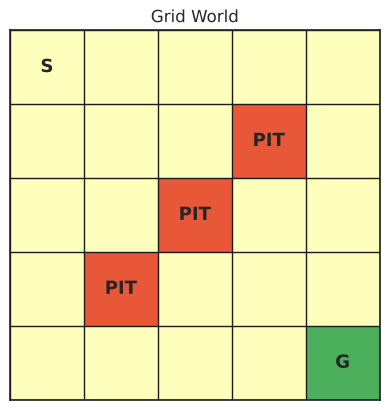

In [2]:
N = 5
START, GOAL = (0, 0), (4, 4)
PITS = {(1, 3), (2, 2), (3, 1)}
ACTIONS = [(-1, 0), (1, 0), (0, -1), (0, 1)]          # up, down, left, right
ARROWS = ["↑", "↓", "←", "→"]
ACTION_NAMES = ["up", "down", "left", "right"]

def step(state, a):
    # Take action a in state; return (next_state, reward, done)
    r, c = state[0] + ACTIONS[a][0], state[1] + ACTIONS[a][1]
    if not (0 <= r < N and 0 <= c < N):
        r, c = state                                   # bumped into a wall: stay
    ns = (r, c)
    if ns == GOAL: return ns, 10, True
    if ns in PITS: return ns, -10, True
    return ns, -1, False

# draw the grid
grid = np.zeros((N, N))
for p in PITS: grid[p] = -1
grid[GOAL] = 1
fig, ax = plt.subplots(figsize=(4.8, 4.8))
ax.imshow(grid, cmap="RdYlGn", vmin=-1.5, vmax=1.5)
for r in range(N):
    for c_ in range(N):
        t = "S" if (r, c_) == START else "G" if (r, c_) == GOAL else "PIT" if (r, c_) in PITS else ""
        ax.text(c_, r, t, ha="center", va="center", fontsize=13, fontweight="bold")
ax.set_xticks(np.arange(-.5, N, 1)); ax.set_yticks(np.arange(-.5, N, 1)); ax.grid(color="k", lw=1)
ax.set_xticklabels([]); ax.set_yticklabels([]); ax.set_title("Grid World"); plt.show()

## Step 2: Q-Learning

The agent keeps a **Q-table** $Q(s,a)$: the expected total future reward for taking action $a$ in state $s$ and then acting well. After every step it updates one entry:

$$Q(s,a) \leftarrow Q(s,a) + \alpha\Big[\, r + \gamma \max_{a'} Q(s',a') - Q(s,a) \Big]$$

- $\alpha$ = learning rate (how fast to learn), $\gamma$ = discount factor (how much future rewards matter)
- The bracket is the **temporal-difference (TD) error**: target minus current estimate.

**Exploration vs exploitation (epsilon-greedy):** with probability $\varepsilon$ take a random action (**explore**); otherwise take the best known action $\arg\max_a Q(s,a)$ (**exploit**). We start with $\varepsilon=1$ (pure exploration) and **decay** it toward a small minimum.

In [3]:
def train(episodes=3000, alpha=0.1, gamma=0.95, eps_start=1.0, eps_min=0.05, eps_decay=0.995,
          max_steps=100, seed=0, q0=0.0):
    rng = np.random.default_rng(seed)
    Q = np.full((N, N, 4), q0, dtype=float)          # initial Q-values (q0 = 0 by default)
    rewards, steps, success, eps_hist = [], [], [], []
    eps = eps_start
    for ep in range(episodes):
        s, total, done, n = START, 0, False, 0
        while not done and n < max_steps:
            if rng.random() < eps:
                a = int(rng.integers(4))                 # explore
            else:
                q = Q[s]
                a = int(rng.choice(np.flatnonzero(q == q.max())))   # exploit (ties broken randomly)
            ns, r, done = step(s, a)
            Q[s][a] += alpha * (r + gamma * (0 if done else Q[ns].max()) - Q[s][a])   # Bellman / TD update
            s, total, n = ns, total + r, n + 1
        rewards.append(total); steps.append(n); success.append(int(s == GOAL))
        eps_hist.append(eps)
        eps = max(eps_min, eps * eps_decay)
    return Q, np.array(rewards), np.array(steps), np.array(success), np.array(eps_hist)

Q, rewards, steps, success, eps_hist = train()
print("Training finished. Q-table shape:", Q.shape)

Training finished. Q-table shape: (5, 5, 4)


## Step 3: Learning curves

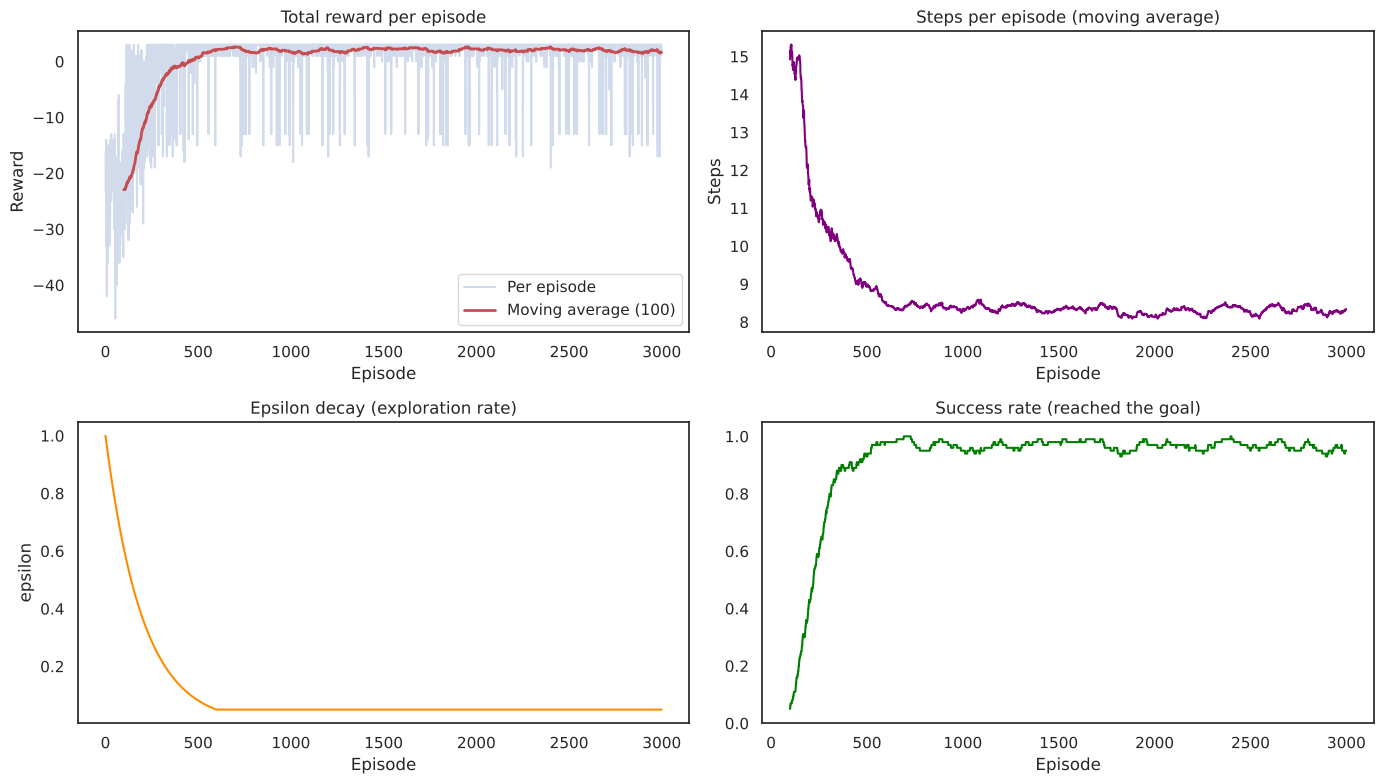

Average reward, first 100 episodes: -22.9 | last 100 episodes: 1.7
Success rate,  first 100 episodes: 0.05 | last 100 episodes: 0.95


In [4]:
def moving_avg(x, w=100):
    return np.convolve(x, np.ones(w) / w, mode="valid")

fig, ax = plt.subplots(2, 2, figsize=(14, 8))
ax[0, 0].plot(rewards, alpha=0.25, label="Per episode"); ax[0, 0].plot(range(99, len(rewards)), moving_avg(rewards), "r", lw=2, label="Moving average (100)")
ax[0, 0].set_title("Total reward per episode"); ax[0, 0].set_xlabel("Episode"); ax[0, 0].set_ylabel("Reward"); ax[0, 0].legend()

ax[0, 1].plot(range(99, len(steps)), moving_avg(steps), color="purple")
ax[0, 1].set_title("Steps per episode (moving average)"); ax[0, 1].set_xlabel("Episode"); ax[0, 1].set_ylabel("Steps")

ax[1, 0].plot(eps_hist, color="darkorange"); ax[1, 0].set_title("Epsilon decay (exploration rate)")
ax[1, 0].set_xlabel("Episode"); ax[1, 0].set_ylabel("epsilon")

ax[1, 1].plot(range(99, len(success)), moving_avg(success), color="green")
ax[1, 1].set_title("Success rate (reached the goal)"); ax[1, 1].set_xlabel("Episode"); ax[1, 1].set_ylim(0, 1.05)
plt.tight_layout(); plt.show()
print("Average reward, first 100 episodes: %.1f | last 100 episodes: %.1f" % (rewards[:100].mean(), rewards[-100:].mean()))
print("Success rate,  first 100 episodes: %.2f | last 100 episodes: %.2f" % (success[:100].mean(), success[-100:].mean()))

**How to read these four graphs**
1. **Reward per episode:** at the start the agent wanders randomly, often falls into pits and gets large negative rewards. As the Q-table improves, the moving average (red) **rises and levels off** near the best achievable value. The shortest safe path is 8 moves: 7 steps at -1 and a final +10 = **+3**. The curve stays slightly below that because of the remaining random exploration (epsilon never reaches 0).
2. **Steps per episode:** early episodes are long (random wandering) or end quickly in a pit; later episodes shrink to about the shortest path length.
3. **Epsilon decay:** exploration starts at 100% and decays to 5%: first learn about the world, then use what was learned.
4. **Success rate:** share of episodes that reach the goal; it climbs towards 1.

## Step 4: Q-values and the optimal policy

In [5]:
def policy_grid(Q):
    pol = np.full((N, N), " ", dtype=object)
    for r in range(N):
        for c_ in range(N):
            if (r, c_) == GOAL: pol[r, c_] = "G"
            elif (r, c_) in PITS: pol[r, c_] = "X"
            else: pol[r, c_] = ARROWS[int(np.argmax(Q[r, c_]))]
    return pol

pol = policy_grid(Q)
print("Learned policy (G = goal, X = pit):")
for row in pol: print("  " + "  ".join(row))

# Follow the greedy policy from the start
s, path, total = START, [START], 0
for _ in range(30):
    a = int(np.argmax(Q[s])); s, r, done = step(s, a); path.append(s); total += r
    if done: break
print("\nGreedy path:", " -> ".join(map(str, path)))
print("Path length:", len(path) - 1, "moves | total reward:", total, "| reached goal:", path[-1] == GOAL)

Learned policy (G = goal, X = pit):
  ↓  ←  →  →  ↓
  ↓  ←  ↑  X  ↓
  ↓  ←  X  ↓  ↓
  ↓  X  ↓  ↓  ↓
  →  →  →  →  G

Greedy path: (0, 0) -> (1, 0) -> (2, 0) -> (3, 0) -> (4, 0) -> (4, 1) -> (4, 2) -> (4, 3) -> (4, 4)
Path length: 8 moves | total reward: 3 | reached goal: True


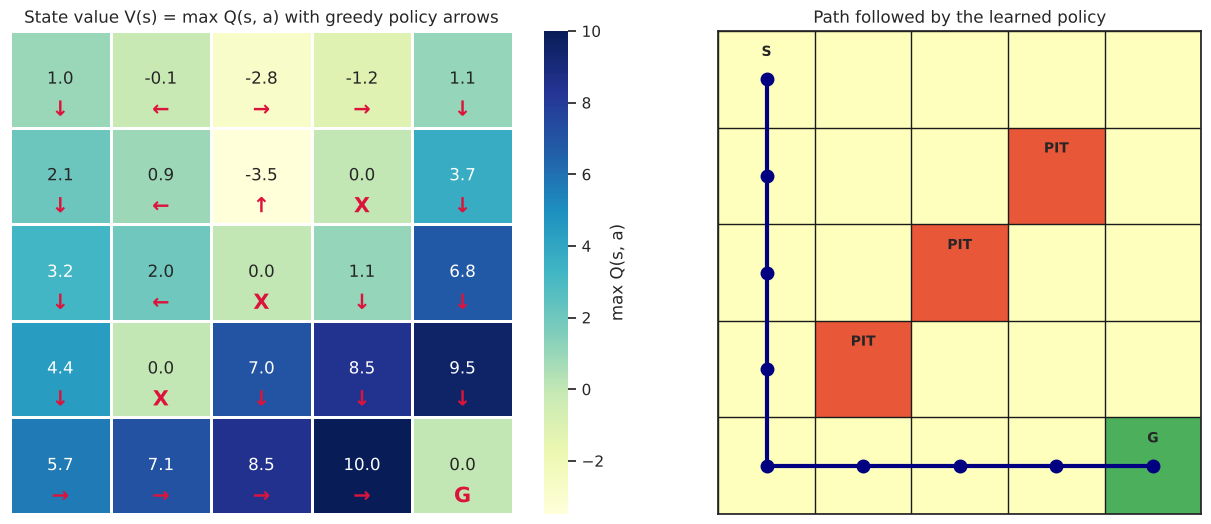

In [6]:
V = Q.max(axis=2)
fig, ax = plt.subplots(1, 2, figsize=(13, 5.4))

# Left: state values with policy arrows
sns.heatmap(V, annot=True, fmt=".1f", cmap="YlGnBu", cbar_kws={"label": "max Q(s, a)"}, ax=ax[0], linewidths=1, linecolor="white")
for r in range(N):
    for c_ in range(N):
        ax[0].text(c_ + 0.5, r + 0.82, pol[r, c_], ha="center", va="center", fontsize=15, color="crimson", fontweight="bold")
ax[0].set_title("State value V(s) = max Q(s, a) with greedy policy arrows"); ax[0].set_xticks([]); ax[0].set_yticks([])

# Right: path drawn on the grid
grid = np.zeros((N, N))
for p in PITS: grid[p] = -1
grid[GOAL] = 1
ax[1].imshow(grid, cmap="RdYlGn", vmin=-1.5, vmax=1.5)
pr, pc = zip(*path)
ax[1].plot(pc, pr, "o-", color="navy", lw=3, ms=9)
for r in range(N):
    for c_ in range(N):
        t = "S" if (r, c_) == START else "G" if (r, c_) == GOAL else "PIT" if (r, c_) in PITS else ""
        ax[1].text(c_, r - 0.28, t, ha="center", va="center", fontsize=10, fontweight="bold")
ax[1].set_xticks(np.arange(-.5, N, 1)); ax[1].set_yticks(np.arange(-.5, N, 1)); ax[1].grid(color="k", lw=1)
ax[1].set_xticklabels([]); ax[1].set_yticklabels([]); ax[1].set_title("Path followed by the learned policy")
plt.tight_layout(); plt.show()

**How to read these**
- **Value heatmap:** each cell shows the best Q-value of that state: how good it is to be there. Values are **highest next to the goal** and **decrease with distance** (because of discounting and the -1 step cost), and cells beside pits are lower. The red arrows give the **optimal policy**: in each state, the action with the highest Q-value.
- **Path plot:** following the arrows from the start leads to the goal while avoiding the pits (and taking the shortest safe route when learning has converged). Cells that the agent rarely visits can have arrows that look arbitrary because the agent never needed them.

## Step 5: Exploration vs exploitation: comparing strategies

| Strategy | Meaning |
|---|---|
| **Greedy** (epsilon = 0), Q starts at 0 | Never explore. All Q-values start at 0, which is *optimistic* here because every step really costs -1 |
| **Greedy, pessimistic start** (epsilon = 0, Q starts at -20) | Never explore, and the table starts *pessimistic* (below any real return) |
| **Low fixed** (epsilon = 0.05) | Almost always exploit |
| **High fixed** (epsilon = 0.5) | Explore half of the time |
| **Decaying** (1.0 → 0.05) | Explore first, exploit later (our default) |

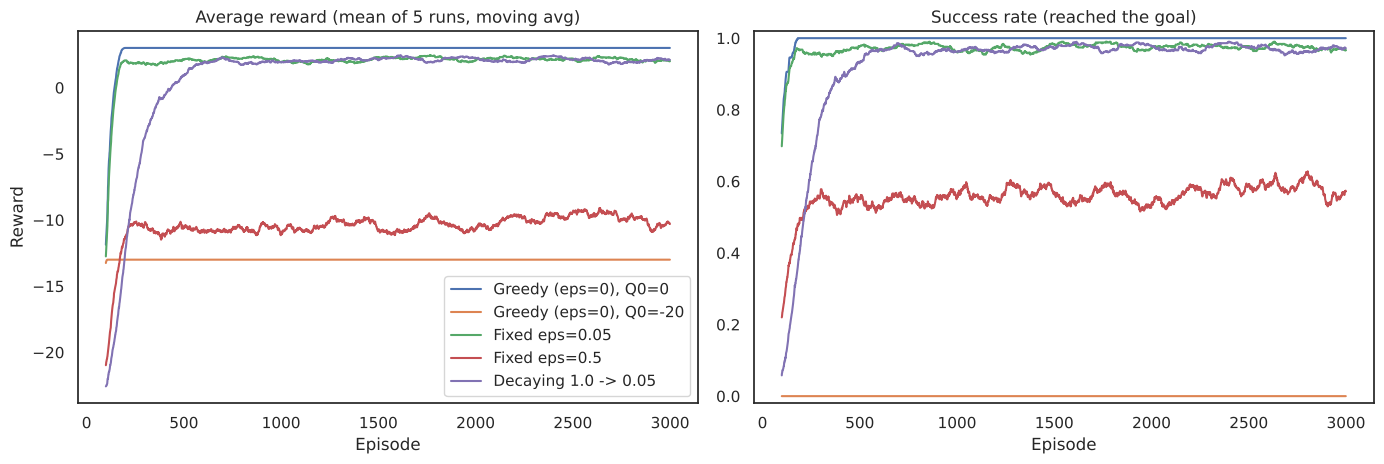

,Avg reward (first 500 eps),Avg reward (last 500 eps),Success rate (last 500 eps),Learned greedy policy reaches goal (of 5 runs)
"Greedy (eps=0), Q0=0",0.03,3.00,1.00,5/5
"Greedy (eps=0), Q0=-20",-13.05,-13.00,0.00,0/5
Fixed eps=0.05,-0.98,2.12,0.97,5/5
Fixed eps=0.5,-12.85,-9.97,0.58,5/5
Decaying 1.0 -> 0.05,-7.67,2.02,0.97,5/5


In [7]:
configs = {
    "Greedy (eps=0), Q0=0": dict(eps_start=0.0, eps_min=0.0, eps_decay=1.0),
    "Greedy (eps=0), Q0=-20": dict(eps_start=0.0, eps_min=0.0, eps_decay=1.0, q0=-20.0),
    "Fixed eps=0.05": dict(eps_start=0.05, eps_min=0.05, eps_decay=1.0),
    "Fixed eps=0.5": dict(eps_start=0.5, eps_min=0.5, eps_decay=1.0),
    "Decaying 1.0 -> 0.05": dict(eps_start=1.0, eps_min=0.05, eps_decay=0.995),
}
def greedy_eval(Qx):
    # Follow the greedy policy from the start; return (total reward, reached goal?)
    s, tot = START, 0
    for _ in range(30):
        s, r, done = step(s, int(np.argmax(Qx[s]))); tot += r
        if done: break
    return tot, s == GOAL

runs, greedy_ok = {}, {}
for name, kw in configs.items():
    all_r, all_s, ok = [], [], 0
    for seed in range(5):                       # average over 5 random seeds
        Qc, r_, s_, su_, _ = train(seed=seed, **kw)
        all_r.append(r_); all_s.append(su_)
        ok += int(greedy_eval(Qc)[1])           # does the learned greedy policy reach the goal?
    runs[name] = (np.mean(all_r, axis=0), np.mean(all_s, axis=0), Qc)
    greedy_ok[name] = f"{ok}/5"

fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
for name, (r_, su_, _) in runs.items():
    ax[0].plot(range(99, len(r_)), moving_avg(r_), label=name)
    ax[1].plot(range(99, len(su_)), moving_avg(su_), label=name)
ax[0].set_title("Average reward (mean of 5 runs, moving avg)"); ax[0].set_xlabel("Episode"); ax[0].set_ylabel("Reward"); ax[0].legend()
ax[1].set_title("Success rate (reached the goal)"); ax[1].set_xlabel("Episode"); ax[1].set_ylim(-0.02, 1.02)
plt.tight_layout(); plt.show()

summary = pd.DataFrame({
    "Avg reward (first 500 eps)": {n: v[0][:500].mean() for n, v in runs.items()},
    "Avg reward (last 500 eps)": {n: v[0][-500:].mean() for n, v in runs.items()},
    "Success rate (last 500 eps)": {n: v[1][-500:].mean() for n, v in runs.items()},
    "Learned greedy policy reaches goal (of 5 runs)": greedy_ok,
}).round(2)
summary

**How to read this comparison (numbers from my run, averaged over 5 seeds; the best possible reward is +3)**

| Strategy | First 500 episodes | Last 500 episodes | What happened |
|---|---|---|---|
| Greedy, Q starts at 0 | about 0 | **3.0** | Learned the best path with **no explicit exploration** |
| Greedy, Q starts at -20 | about -13 | **-13** (never improves) | **Failed**: never reached the goal |
| Fixed eps = 0.05 | about -1 | 2.1 | Good |
| Fixed eps = 0.5 | about -13 | **-10** (success 58%) | Learned a correct policy, but acts randomly half the time |
| Decaying 1.0 → 0.05 | about -8 | 2.0 | Good, but worst early on because it starts with 100% random moves |

**Why does the greedy agent work when Q starts at 0? (important, and surprising)** Every real step costs -1, so any action already tried has a Q-value *below 0*, while untried actions still look like 0, i.e. *better*. The greedy agent is therefore pushed to try untried actions: this is called **optimistic initialisation**, and it acts as a built-in form of exploration. It is a property of this environment (all rewards negative except the goal) and of starting Q at 0, **not** a general rule. When the table starts pessimistic (-20), untried actions look worse than anything the agent has seen, so a greedy agent never tries them and never reaches the goal: **this is why exploration is normally necessary.**

**Other points**
- **Fixed eps = 0.5** has a low *measured* reward (-10) because half its actions are random (often into pits), but its learned Q-table is fine: following it greedily reaches the goal (5/5 runs). This shows the difference between the **behaviour policy** (what the agent does while learning) and the **learned policy** (what it knows).
- **Decaying epsilon vs small fixed epsilon:** on this small, easy grid they end at the same performance (about 2.0 to 2.1: the small gap is noise). Decaying epsilon is not better here; it pays off in larger or harder problems where early exploration is needed to find rewards and late exploitation is needed to collect them.

## Step 6: Effect of learning rate (alpha) and discount factor (gamma)

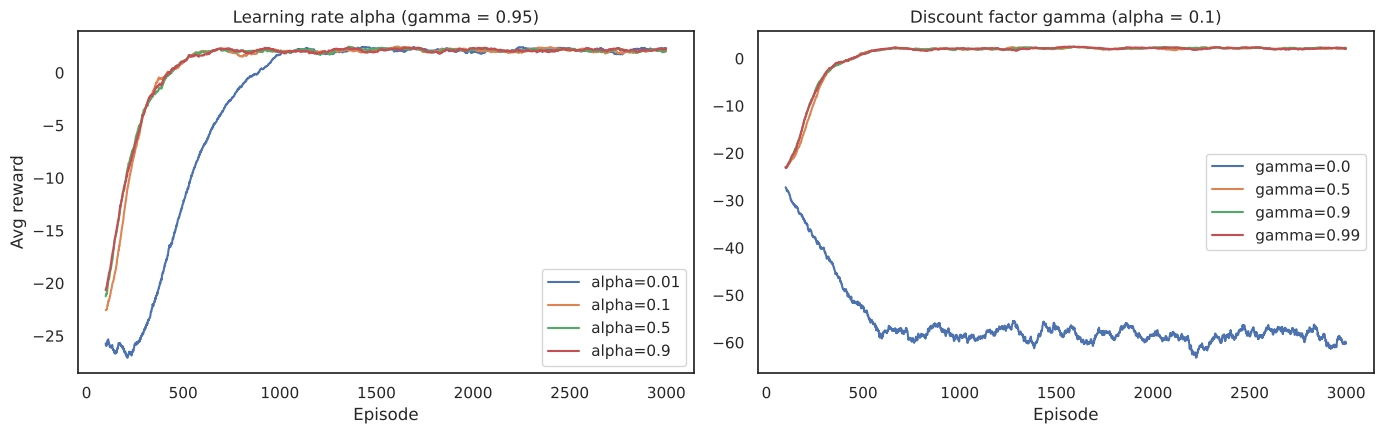

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for a_ in [0.01, 0.1, 0.5, 0.9]:
    r_ = np.mean([train(alpha=a_, seed=s)[1] for s in range(4)], axis=0)
    ax[0].plot(range(99, len(r_)), moving_avg(r_), label=f"alpha={a_}")
ax[0].set_title("Learning rate alpha (gamma = 0.95)"); ax[0].set_xlabel("Episode"); ax[0].set_ylabel("Avg reward"); ax[0].legend()

for g_ in [0.0, 0.5, 0.9, 0.99]:
    r_ = np.mean([train(gamma=g_, seed=s)[1] for s in range(4)], axis=0)
    ax[1].plot(range(99, len(r_)), moving_avg(r_), label=f"gamma={g_}")
ax[1].set_title("Discount factor gamma (alpha = 0.1)"); ax[1].set_xlabel("Episode"); ax[1].legend()
plt.tight_layout(); plt.show()

**How to read these (numbers from my run):**
- **Alpha:** all four learning rates end at the same level (about 2.1). The difference is in the **speed**: alpha = 0.01 is clearly the slowest (average reward in the first 300 episodes is about -26, versus about -12 for alpha 0.1 to 0.9). Alpha = 0.9 did *not* become unstable here, because this grid world is **deterministic** (the same action always gives the same result), so overwriting old estimates with new ones is harmless. In a **stochastic** environment, a large alpha would make Q-values jump around with every noisy outcome, so a small or decaying alpha is preferred there.
- **Gamma:** with **gamma = 0** the agent is completely short-sighted: it only values the immediate reward, so the +10 at the goal never propagates back to earlier states, and it never learns to reach the goal (average reward stays very negative, about -58, and the learned policy fails in all runs). Any gamma from **0.5 upward** worked on this small 5x5 grid (final reward about 2.1). Higher gamma matters more for larger grids, where the goal is further away.

## Result / Conclusion
- The agent learned a policy that goes from the start to the goal in 8 moves (the shortest safe path, return +3) while avoiding all pits. Its average reward improved from about -23 in the first 100 episodes to about +1.7 in the last 100 (success rate 5% to 95%); it stays below +3 because epsilon never reaches 0.
- **Exploration matters**: a greedy agent only works here because of the optimistic start (Q = 0 with negative step costs); with a pessimistic start it never reaches the goal. **Too much exploration lowers measured performance** (fixed epsilon = 0.5), though the learned table is still correct. Small fixed epsilon and decaying epsilon performed the same on this easy problem.
- Gamma must be above 0 for the goal reward to propagate backwards; alpha mainly controls the speed of learning (and stability in noisy environments).

---
# Viva Questions and Answers

## A. Concept questions

**Q1. What is reinforcement learning?**
A learning paradigm where an agent interacts with an environment, takes actions, receives rewards, and learns a policy that maximises cumulative reward.

**Q2. Define agent, environment, state, action, reward and policy.**
Agent: the learner. Environment: the world it acts in. State: the current situation. Action: a choice the agent makes. Reward: scalar feedback. Policy: a mapping from states to actions.

**Q3. What is Q-Learning?**
A model-free, off-policy, value-based RL algorithm that learns the action-value function $Q(s,a)$: the expected total future reward for taking action a in state s and then acting optimally.

**Q4. Explain the Q-learning update rule.**
New Q = old Q + $\alpha$ × (reward + $\gamma$ × best next Q − old Q). The bracket is the temporal-difference (TD) error: the gap between the target and the current estimate.

**Q5. What is the learning rate α?**
How much new information overrides old. 0 means no learning; 1 means only the latest experience is used. Typical value about 0.1.

**Q6. What is the discount factor γ?**
Controls how much future rewards matter. Near 0: short-sighted; near 1: far-sighted. Typical 0.9 to 0.99.

**Q7. What is exploration vs exploitation?**
Exploration: trying new actions to discover better rewards. Exploitation: using current knowledge to pick the best-known action. Both are needed.

**Q8. What is epsilon-greedy?**
With probability ε choose a random action (explore); with probability 1 − ε choose the action with the highest Q (exploit). ε is usually decayed over time.

**Q9. Why decay epsilon?**
Early on, the Q-table is uninformed, so explore a lot. Later the policy is good, so exploit more and earn higher rewards.

**Q10. What does "model-free" mean?**
The agent does not know or learn the environment's transition probabilities or reward function; it learns directly from experience.

**Q11. What does "off-policy" mean?**
Q-learning updates using the greedy best next action (max Q), regardless of which action the behaviour policy actually takes. SARSA is on-policy: it uses the action actually taken.

**Q12. Q-Learning vs SARSA?**
Q-learning's target uses $\max_{a'}Q(s',a')$, so it learns the optimal policy and is more optimistic (it takes risks near pits). SARSA uses the $Q(s',a')$ of the action actually taken, so it learns a safer policy that accounts for its own exploration.

**Q13. What is the Q-table?**
A table with one row per state and one column per action, storing Q-values.

**Q14. What is the optimal policy?**
The policy that maximises expected cumulative reward from every state; derived as $\pi^*(s)=\arg\max_a Q(s,a)$.

**Q15. What is the Bellman equation?**
$Q^*(s,a)=E[\,r+\gamma\max_{a'}Q^*(s',a')\,]$: the value of a state-action equals the immediate reward plus the discounted best value of the next state. Q-learning is a sample-based way to solve it.

**Q16. What are the limitations of tabular Q-learning?**
It does not scale to large or continuous state spaces (the table explodes). Solution: function approximation such as Deep Q-Networks (DQN).

**Q17. What is an episode?**
One complete run from the start state until a terminal state (goal or pit) or a step limit.

**Q18. What is a Markov Decision Process (MDP)?**
The mathematical framework for RL: states, actions, transition probabilities, rewards and a discount factor; the next state depends only on the current state and action (Markov property).

**Q19. Does Q-learning always converge?**
In the tabular case, yes to the optimal Q-values, provided every state-action pair is visited infinitely often and the learning rate decays appropriately.

**Q20. Why is the step reward −1?**
It penalises long paths, so the agent prefers the shortest route to the goal instead of wandering.

**Q21. Why are pits given −10 and the goal +10?**
Terminal rewards signal good and bad outcomes. Falling in a pit ends the episode with a big penalty, so the agent learns to avoid it; reaching the goal gives a big reward that propagates backwards through Q-values.

**Q22. What is the difference between reward and value (Q)?**
Reward is the immediate feedback for one step. Value/Q is the expected sum of all future (discounted) rewards.

**Q23. What is the credit assignment problem?**
Deciding which earlier actions deserve credit for a delayed reward. Q-learning solves it by propagating value backwards through the TD updates.

**Q24. How does RL differ from supervised learning?**
There are no labelled examples; feedback is a delayed, evaluative reward signal, and the agent's actions affect the data it sees later.

**Q25. What is a terminal state?**
A state where the episode ends (goal or pit); its future value is 0, so the update there uses only the immediate reward.

**Q26. Real-world uses of RL?**
Games (Go, Atari), robotics, recommendation systems, resource scheduling, autonomous driving, and tuning language models from human feedback.

## B. Questions about the graphs

**G1. What does the learning curve (reward vs episode) show?**
Learning progress. It starts low and noisy (exploration, many pit falls), rises as Q-values improve, and flattens near the maximum when the policy has converged.

**G2. Why is the curve noisy even at the end?**
Because epsilon never reaches 0 (minimum 0.05), the agent still takes occasional random actions. A moving average smooths it.

**G3. Why does the reward level off around +3 and not +10?**
The goal gives +10 but each of the 7 earlier steps costs −1, so the best possible return is 10 − 7 = +3 on the shortest path.

**G4. How do you read the policy grid?**
Each cell shows the best action (arrow) from that state, i.e. argmax Q(s, a). Following the arrows from the start should reach the goal while avoiding pits.

**G5. What does the value heatmap show?**
The maximum Q-value in each state. Values are highest next to the goal and fall with distance (discounting); cells next to pits are lower.

**G6. What does the epsilon decay plot show?**
Epsilon falling from 1.0 to 0.05: mostly exploration at first, mostly exploitation at the end.

**G7. Compare the curves for different epsilon strategies.**
A very high fixed epsilon (0.5) learns a correct Q-table but keeps getting low rewards (about -10) because it keeps acting randomly. A small fixed epsilon (0.05) and a decaying epsilon both end near +2 (the best possible is +3), and the decaying one is worst at the start because it begins with 100% random moves. The greedy agent with Q starting at 0 also learns well (optimistic initialisation), but a greedy agent with a pessimistic start (-20) never reaches the goal.

**G7b. Your greedy agent (epsilon = 0) learned the optimal policy with no exploration. Does that mean exploration is useless?**
No. It worked only because Q was initialised to 0 while every step costs -1: untried actions look better than tried ones (optimistic initialisation), which forces the agent to try them. With a pessimistic initial Q-table (-20) the same greedy agent never reaches the goal. In general, and especially with positive or sparse rewards, an agent needs deliberate exploration such as epsilon-greedy.

**G8. What does the steps-per-episode plot show?**
Episodes become shorter as the agent learns the direct route, ending near the shortest path length (8 moves).

**G9. What does the success-rate curve show?**
The fraction of episodes that reach the goal; it rises toward 1 as the policy improves.

**G10. What do the alpha and gamma plots show?**
Alpha controls learning speed: alpha = 0.01 is much slower, while 0.1 to 0.9 all reach the same final reward in this deterministic grid (a large alpha would be noisy in a stochastic environment). Gamma = 0 makes the agent short-sighted so it cannot learn the path to the goal; gamma of 0.5 and above lets the goal reward propagate back.

**G11. What is optimistic initialisation?**
Starting Q-values higher than the true values, so every untried action looks attractive and the agent explores them even when it acts greedily. In this grid, Q = 0 is optimistic because real returns are negative (-1 per step).

## C. Code questions

**C1. What does `Q[s][a] += alpha * (r + gamma * Q[ns].max() - Q[s][a])` do?**
The Q-learning (Bellman/TD) update for the state-action just taken.

**C2. Why is the next-state value set to 0 when `done`?**
A terminal state has no future, so the target is just the immediate reward.

**C3. Why break ties randomly in exploitation?**
At the start all Q-values are 0, so `argmax` would always pick action 0 and bias exploration; random tie-breaking avoids that.

**C4. Why `max_steps = 100`?**
To stop endless episodes if the agent wanders without reaching a terminal state.

**C5. Why average over several random seeds in Step 5?**
RL results are noisy because of random exploration; averaging gives a fairer comparison.